# 03 — Baseline fenotípico: árvore de decisão × Random Forest × XGBoost

**Tarefa:** classificar Controle, TDAH e TEA na coorte pareada por sexo e idade (`data/processed/cohort_matched.csv`,
912 sujeitos, notebook 02).

**Features:** só o fenótipo comum às duas bases (idade, sexo, QI total, verbal, de execução e discrepância VIQ − PIQ).
Escalas clínicas (ADOS, ADI-R, ADHD index) ficam fora, porque cada uma só existe numa base e revelaria o rótulo.

**Validação:** `GroupKFold` embaralhado com 5 dobras agrupadas por **instituição** (a instituição de teste nunca aparece no treino),
repetido com 10 sementes. (`StratifiedGroupKFold` foi descartado: com poucas instituições ele gera a mesma divisão para qualquer semente.) Acaso para 3 classes balanceadas = acurácia balanceada de **0,33**.

Código em `src/evaluation.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from evaluation import (CLASSES, RANDOM_STATE, confusion_table, features, make_models, repeated_group_cv, target)
from matching import dataset_bias_test

FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

d = pd.read_csv(ROOT / "data" / "processed" / "cohort_matched.csv")
X, y, sitio = features(d, "qi"), target(d), d["institution"]
print(X.shape, dict(zip(CLASSES, np.bincount(y))))
X.describe().T.round(1)

(1136, 6) {'Controle': np.int64(568), 'TDAH': np.int64(284), 'TEA': np.int64(284)}


,count,mean,std,min,25%,50%,75%,max
idade,1136.0,11.7,2.8,7.0,9.5,11.4,13.4,20.6
sexo_m,1136.0,0.8,0.4,0.0,1.0,1.0,1.0,1.0
qi_total,1053.0,109.7,15.2,41.0,100.0,109.0,120.0,153.0
qi_verbal,865.0,110.9,16.3,42.0,99.0,111.0,122.0,180.0
qi_execucao,877.0,105.7,15.7,37.0,95.0,106.0,117.0,157.0
discrep_viq_piq,855.0,4.8,15.9,-43.0,-6.0,5.0,15.0,65.0


## 0. Checagem: as features novas (VIQ, PIQ) denunciam a base?
Mesmo teste do notebook 01, agora com o conjunto de features do modelo, só entre controles.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from evaluation import _imputer

ctrl = d.diagnosis == "Controle"
m = make_pipeline(_imputer(RANDOM_STATE), RandomForestClassifier(500, min_samples_leaf=5, class_weight="balanced",
                                                                 random_state=RANDOM_STATE))
s = cross_val_score(m, X[ctrl], (d.dataset[ctrl] == "ABIDE").astype(int), groups=sitio[ctrl],
                    cv=StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="balanced_accuracy")
print(f"Prever a base entre controles com as features do modelo: {s.mean():.3f} ± {s.std():.3f} (acaso 0,50)")

Prever a base entre controles com as features do modelo: 0.505 ± 0.068 (acaso 0,50)


## 1. Desempenho com validação por sítio (10 repetições)

In [3]:
resultados, oof = {}, {}
for nome, modelo in make_models().items():
    resultados[nome], oof[nome] = repeated_group_cv(modelo, X, y, sitio, seeds=range(10))

resumo = pd.concat({n: r.drop(columns="semente").agg(["mean", "std"]).T for n, r in resultados.items()}, axis=1)
resumo.round(3)

Árvore de decisão        Random Forest        XGBoost       
                               mean    std          mean    std    mean    std
acc_balanceada                0.396  0.019         0.383  0.014   0.374  0.018
sens_Controle                 0.573  0.103         0.532  0.029   0.546  0.029
sens_TDAH                     0.297  0.096         0.214  0.026   0.204  0.021
sens_TEA                      0.319  0.095         0.402  0.024   0.371  0.021
auc_macro_ovr                 0.566  0.012         0.555  0.013   0.547  0.013
confusao_TEA_TDAH             0.304  0.038         0.315  0.024   0.318  0.024

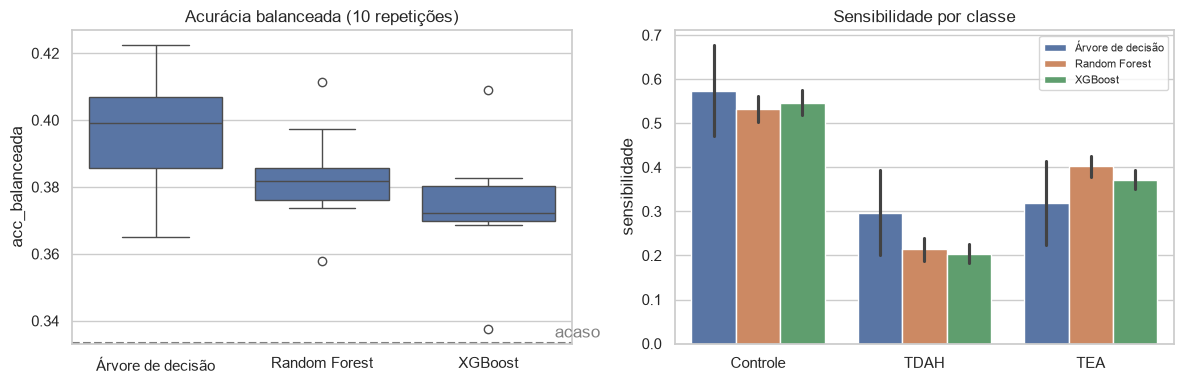

In [4]:
longo = pd.concat([r.assign(modelo=n) for n, r in resultados.items()])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=longo, x="modelo", y="acc_balanceada", ax=ax[0]); ax[0].axhline(1/3, ls="--", c="gray")
ax[0].set_title("Acurácia balanceada (10 repetições)"); ax[0].set_xlabel(""); ax[0].text(2.4, 0.335, "acaso", color="gray")
sens = longo.melt(id_vars="modelo", value_vars=["sens_Controle", "sens_TDAH", "sens_TEA"], var_name="classe", value_name="sensibilidade")
sens["classe"] = sens["classe"].str.replace("sens_", "")
sns.barplot(data=sens, x="classe", y="sensibilidade", hue="modelo", ax=ax[1], errorbar="sd")
ax[1].set_title("Sensibilidade por classe"); ax[1].set_xlabel(""); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_baseline_fenotipo_metricas.png", dpi=150)

### Comitê × árvore: a diferença é consistente?
Diferença pareada por semente (mesmas dobras para os três modelos) e teste de Wilcoxon. Com só 10 repetições
de CV, que não são independentes, o p-valor é indicativo.

In [5]:
arv = resultados["Árvore de decisão"]
linhas = []
for nome in ["Random Forest", "XGBoost"]:
    for met in ["acc_balanceada", "confusao_TEA_TDAH"]:
        dif = resultados[nome][met] - arv[met]
        linhas.append({"comparação": f"{nome} − Árvore", "métrica": met, "diferença_média": dif.mean(),
                       "dp": dif.std(), "p_wilcoxon": stats.wilcoxon(dif).pvalue})
pd.DataFrame(linhas).round(3)

,comparação,métrica,diferença_média,dp,p_wilcoxon
0,Random Forest − Árvore,acc_balanceada,-0.014,0.026,0.154
1,Random Forest − Árvore,confusao_TEA_TDAH,0.011,0.047,0.826
2,XGBoost − Árvore,acc_balanceada,-0.023,0.028,0.027
3,XGBoost − Árvore,confusao_TEA_TDAH,0.014,0.048,0.492


## 2. Matrizes de confusão (semente 0, predições fora da dobra)

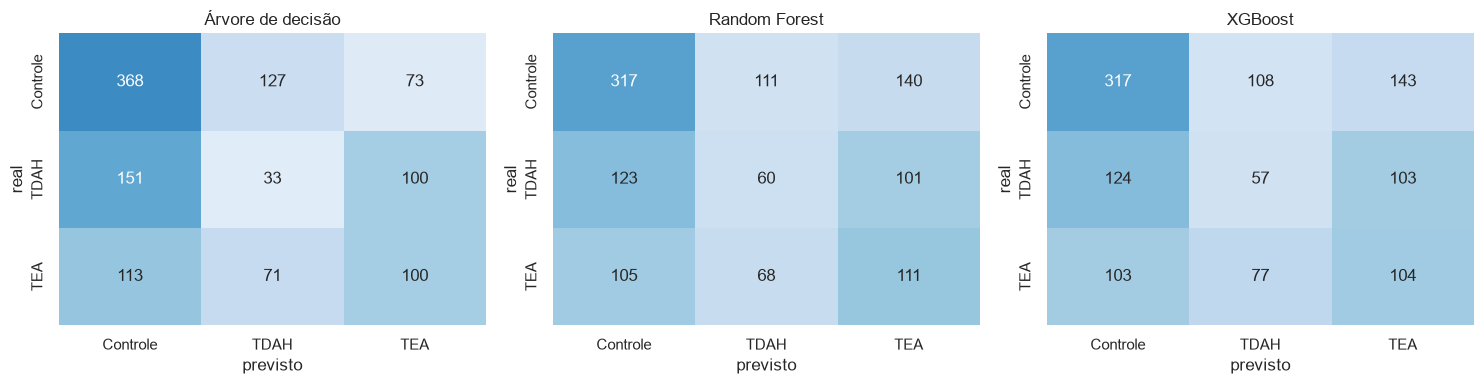

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (nome, p) in zip(ax, oof.items()):
    cm = confusion_table(y, p)
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=cm.values, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=CLASSES, yticklabels=CLASSES)
    a.set_title(nome); a.set_xlabel("previsto"); a.set_ylabel("real")
fig.tight_layout(); fig.savefig(FIG / "03_baseline_fenotipo_confusao.png", dpi=150)

## 3. A árvore interpretável
Árvore de profundidade 3 treinada com todos os dados, para mostrar os pontos de corte. O desempenho dela é o da seção 1, não o de treino.

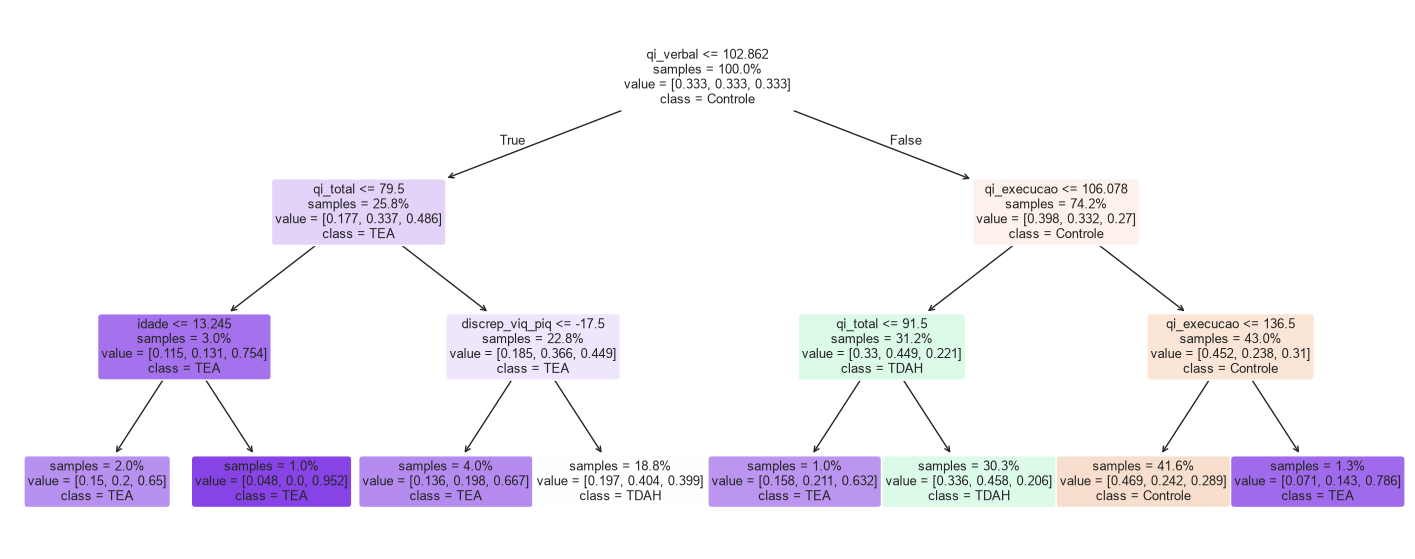

In [7]:
arvore = make_models()["Árvore de decisão"].fit(X, y)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvore[-1], feature_names=X.columns, class_names=CLASSES, filled=True, rounded=True, impurity=False,
          proportion=True, fontsize=9, ax=ax)
fig.savefig(FIG / "03_arvore_fenotipo.png", dpi=150, bbox_inches="tight")

### Sensibilidade à profundidade da árvore

In [8]:
prof = []
for depth in [1, 2, 3, 4, 5, 6, 8]:
    r, _ = repeated_group_cv(make_models(tree_depth=depth)["Árvore de decisão"], X, y, sitio, seeds=range(10))
    prof.append({"profundidade": depth, "acc_bal_média": r.acc_balanceada.mean(), "dp": r.acc_balanceada.std()})
pd.DataFrame(prof).round(3)

,profundidade,acc_bal_média,dp
0,1,0.423,0.020
1,2,0.407,0.020
2,3,0.396,0.019
3,4,0.399,0.033
4,5,0.392,0.016
5,6,0.383,0.020
6,8,0.371,0.021


## 4. Quais features o Random Forest usa?
Importância por permutação nas predições fora da dobra seria o ideal; aqui, por simplicidade, numa divisão por sítio única.

sexo_m            -0.003
idade             -0.002
qi_execucao        0.017
discrep_viq_piq    0.023
qi_verbal          0.027
qi_total           0.031
dtype: float64

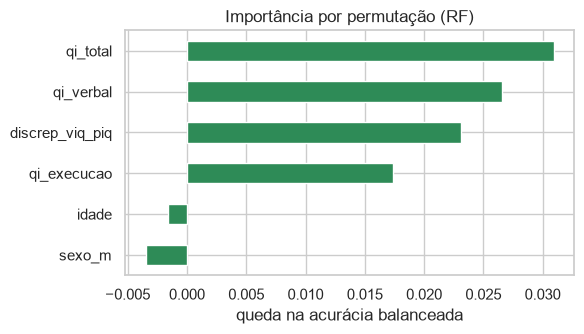

In [9]:
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE).split(X, y, sitio))
rf = make_models()["Random Forest"].fit(X.iloc[tr], y[tr])
pi = permutation_importance(rf, X.iloc[te], y[te], scoring="balanced_accuracy", n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
ax = imp.plot.barh(color="seagreen", figsize=(6, 3.5)); ax.set_xlabel("queda na acurácia balanceada")
ax.set_title("Importância por permutação (RF)"); plt.tight_layout(); plt.savefig(FIG / "03_importancia_rf_fenotipo.png", dpi=150)
imp.round(3)

## 5. Leitura dos resultados (execução de 25/11/2026, com ABIDE II)

- **Só com fenótipo, o sinal é fraco.** A árvore chega a acurácia balanceada de **0,40 ± 0,02**
  (acaso = 0,33; AUC macro 0,57). Random Forest (0,38) e XGBoost (0,37) não superam a árvore
  (diferença −0,01, p = 0,15, e −0,02, p = 0,03).
- **TDAH continua a classe mais difícil** (sensibilidade 0,20–0,30). Cerca de 30% dos casos TEA/TDAH reais são
  classificados como o outro transtorno.
- **A árvore tem leitura clínica:** QI verbal baixo, ou QI verbal muito abaixo do de execução (discrepância ≤ −17,5),
  aponta TEA, um perfil cognitivo descrito na literatura. QI verbal e de execução altos apontam controle.
- **Árvores rasas generalizam melhor** (profundidade 1: 0,42; 8: 0,37). Não há estrutura complexa a aprender.
- **As features do modelo não denunciam a base** (0,51 entre controles).
- Somar o ABIDE II aumentou a amostra pareada de 912 para 1136, mas não mudou a conclusão.

**Conclusão para o projeto:** o fenótipo comum às bases não basta para diferenciar TEA, TDAH e controles. Para testar a
hipótese do canvas (comitê > árvore) são necessárias features com mais sinal: escalas clínicas e cognitivas aplicadas a
todos os grupos (HBN, mediante termo de uso) e/ou derivados de neuroimagem do mesmo pipeline.

**Limitações:** amostra majoritariamente masculina e de 7–21 anos; TEA só de bases ABIDE e TDAH só do ADHD-200;
VIQ/PIQ ausentes em ~23% (imputados); pareamento com uma única semente (42).